In [6]:
import pandas as pd
import numpy as np
import nltk

In [ ]:
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import scipy.sparse as sp
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.naive_bayes import MultinomialNB

from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix

import re

#les fichiers de stopwords pour le français
nltk.download('stopwords')

#le stemmer pour le français
stemmer_fr = SnowballStemmer('french')

#les données nécessaires pour NLTK
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw')


[nltk_data] Downloading package stopwords to /Users/troix/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /Users/troix/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/troix/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw to /Users/troix/nltk_data...
[nltk_data]   Package omw is already up-to-date!


True

In [56]:
import pandas as pd

splits = {'train': 'allocine/train-00000-of-00001.parquet', 'validation': 'allocine/validation-00000-of-00001.parquet', 'test': 'allocine/test-00000-of-00001.parquet'}
df = pd.read_parquet("hf://datasets/tblard/allocine/" + splits["train"])
valdf = pd.read_parquet("hf://datasets/tblard/allocine/" + splits["validation"])
testdf = pd.read_parquet("hf://datasets/tblard/allocine/" + splits["test"])

In [80]:
dftrain = df
dfval = valdf
dftest = testdf

<Axes: ylabel='count'>

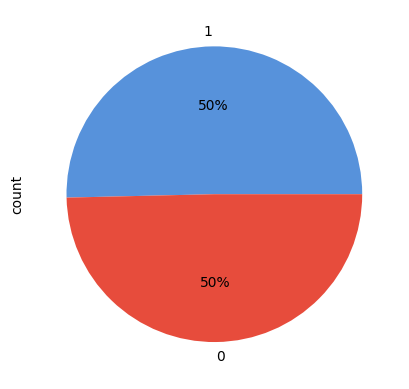

In [58]:
df['label'].value_counts().plot(kind='pie', autopct='%1.0f%%', colors=["#5792db", "#e74c3c"])

In [81]:
stopwords = {"le", "la", "les", "de", "des", "et", "un", "une", "à", "que", "en", ',', '.',
             'film', 'pas', 'est', 'en', 'qui', 'que', 'ce', 'qui', 'en', 'ce', 'du', '!',
             'a', 'avec', 'c', 'd', 'dan', 'est', 'il', 'l', 'le', 'mais', 'n', 'ne', 'on',
             'plus', 'pour', 'se', 'tout', 'très', 'un', 'au', 'bien', 'c', 'd', 'dan', 'est',
             'film', 'il', 'je', 'l', 'le', 'n', 'par', 'qu', 'son', 'sur', 'un',
             'aussi', 'bon', 'cette', 'comme', 'dans', 'fait', 'histoire', 'j', 'même', 'nous',
             's', 'sa', 'sans', 'si', 'sont', 'très', 'voir', 'y', 'ça', 'être'}

def nettoyer(texte):
    texte = texte.lower()
    texte = re.sub(r"[^a-zàâäéèêëîïôöùûüç\s]", " ", texte)
    return texte

def pretrait(text):
    mots = nltk.word_tokenize(text, language='french') #découpe en mots
    #mots_racinise = [stemmer_fr.stem(mot) for mot in mots] #racine du mot
    return " ".join(mots) #.join(mots_racinise)

def enlever_stopwords(texte):
    mots = texte.split()
    mots = [mot for mot in mots if mot not in stopwords]
    return " ".join(mots)

In [82]:
# appliquer les traitements sur les textes
dftrain['texte_clean'] = dftrain['review'].apply(nettoyer).apply(pretrait).apply(enlever_stopwords)
dfval['texte_clean'] = dfval['review'].apply(nettoyer).apply(pretrait).apply(enlever_stopwords)
dftest['texte_clean'] = dftest['review'].apply(nettoyer).apply(pretrait).apply(enlever_stopwords)

In [83]:
dftrain

,review,label,texte_clean
0,Si vous cherchez du cinéma abrutissant à tous ...,0,vous cherchez cinéma abrutissant tous étages a...
1,"Trash, re-trash et re-re-trash...! Une horreur...",0,trash re trash re re trash horreur nom imagine...
2,"Et si, dans les 5 premières minutes du film, l...",0,premières minutes pathétique maquette train fe...
3,Mon dieu ! Quelle métaphore filée ! Je suis ab...,0,mon dieu quelle métaphore filée suis abasourdi...
4,"Premier film de la saga Kozure Okami, ""Le Sabr...",1,premier saga kozure okami sabre vengeance mêle...
...,...,...,...
159995,Un rythme bien trop lent et un Ashton Kutcher ...,0,rythme trop lent ashton kutcher trop nul
159996,Monsieur Duchovny vous êtes aussi piètre acteu...,0,monsieur duchovny vous êtes piètre acteur réal...
159997,Complètement différent des films de la série C...,1,complètement différent films série conjuring n...
159998,Alors franchement pour le moment c'est le meil...,1,alors franchement moment meilleur films noël m...


#### comptage + naive bayes
on doit constrituer un vocabulaire avec les mots les plus fréquents  dans le corpus lorsque le label est négatif et lorsque le label est positif. On va ensuite compter le nombre d'occurences de chaque mot dans les documents et construire une matrice de comptage. Ensuite, on va utiliser cette matrice pour entraîner un classifieur Naive Bayes.


à remettre plus haut

```python
# comptage (vocabulaire + matrice de comptage), vocab de 16 mots les plus fréquents pour chaque label

import pandas as pd
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix

# --- 0. Chargement des 3 splits ---
splits = {
    'train': 'allocine/train-00000-of-00001.parquet',
    'validation': 'allocine/validation-00000-of-00001.parquet',
    'test': 'allocine/test-00000-of-00001.parquet'
}

df_train = pd.read_parquet("hf://datasets/tblard/allocine/" + splits["train"])
df_val   = pd.read_parquet("hf://datasets/tblard/allocine/" + splits["validation"])
df_test  = pd.read_parquet("hf://datasets/tblard/allocine/" + splits["test"])

# (ici df_train correspond à ton "df" prétraité + dédoublonné avec review/label/texte_pretraite)
# ⚠️ il faut appliquer le même prétraitement + dédoublonnage sur df_val et df_test aussi,
# sinon la colonne "texte_pretraite" n'existera pas dessus.
```

In [84]:
#top 16 mots plus fréquents par label
vocab_label = {}
for label, groupe in dftrain.groupby("label"):
    mots = " ".join(groupe["texte_clean"]).split()
    top16 = [mot for mot, _ in Counter(mots).most_common(16)]
    vocab_label[label] = top16
    print(f"Label {label} ({'positif' if label==1 else 'négatif'}) :")
    print(top16, "\n")

# vocabulaire global, union
vocab_global = sorted(set(w for mots in vocab_label.values() for w in mots))
print(f"Taille du vocabulaire global : {len(vocab_global)} mots")
print(vocab_global)

Label 0 (négatif) :
['peu', 'rien', 'scénario', 'ou', 'ai', 'faire', 'trop', 'acteurs', 'mal', 'vraiment', 'peut', 'vous', 'scène', 'ses', 'elle', 'assez'] 

Label 1 (positif) :
['ou', 'ai', 'ses', 'peu', 'acteurs', 'scène', 'aux', 'vraiment', 'elle', 'peut', 'cinéma', 'scénario', 'grand', 'personnages', 'vous', 'tous'] 

Taille du vocabulaire global : 21 mots
['acteurs', 'ai', 'assez', 'aux', 'cinéma', 'elle', 'faire', 'grand', 'mal', 'ou', 'personnages', 'peu', 'peut', 'rien', 'scène', 'scénario', 'ses', 'tous', 'trop', 'vous', 'vraiment']


In [85]:
# --- 3. Matrice de comptage (bag-of-words) avec ce vocabulaire fixé ---
vectorizer = CountVectorizer(vocabulary=vocab_global)

X_train_counts = vectorizer.fit_transform(dftrain["texte_clean"])
X_val_counts   = vectorizer.transform(dfval["texte_clean"])
X_test_counts  = vectorizer.transform(dftest["texte_clean"])

y_train = dftrain["label"]
y_val   = dfval["label"]
y_test  = dftest["label"]

In [86]:
# Visualiser la matrice de comptage (train)
matrice_df = pd.DataFrame(
    X_train_counts.toarray(),
    columns=vectorizer.get_feature_names_out()
)
print(matrice_df.head())

# --- 4. Naive Bayes ---
nb = MultinomialNB()
nb.fit(X_train_counts, y_train)

# --- 5. Évaluation sur validation ---
y_val_pred = nb.predict(X_val_counts)
print("\n--- Validation ---")
print(classification_report(y_val, y_val_pred, target_names=["négatif", "positif"]))
print(confusion_matrix(y_val, y_val_pred))

# --- 6. Évaluation finale sur test ---
y_test_pred = nb.predict(X_test_counts)
print("\n--- Test ---")
print(classification_report(y_test, y_test_pred, target_names=["négatif", "positif"]))
print(confusion_matrix(y_test, y_test_pred))

   acteurs  ai  assez  aux  cinéma  elle  faire  grand  mal  ou  ...  peu  \
0        0   0      0    1       1     0      4      0    0   2  ...    0   
1        0   0      0    0       0     0      0      0    0   1  ...    0   
2        0   0      0    0       0     0      0      0    0   0  ...    0   
3        0   3      0    1       0     0      1      0    0   0  ...    0   
4        0   0      0    0       0     0      0      0    0   0  ...    0   

   peut  rien  scène  scénario  ses  tous  trop  vous  vraiment  
0     0     0      0         1    0     1     0     2         0  
1     0     0      0         0    0     0     2     1         0  
2     1     0      0         0    0     1     1     0         0  
3     0     3      0         0    0     1     0     3         1  
4     0     0      0         0    0     0     0     0         0  

[5 rows x 21 columns]

--- Validation ---
              precision    recall  f1-score   support

     négatif       0.69      0.51      0.58

In [ ]:
# tfidf + reg logistique

tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df['texte_pretraite'])
y = df['label']

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.91753125
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.91      0.92     15883
           1       0.91      0.92      0.92     16117

    accuracy                           0.92     32000
   macro avg       0.92      0.92      0.92     32000
weighted avg       0.92      0.92      0.92     32000

Confusion Matrix:
[[14498  1385]
 [ 1254 14863]]


In [29]:
# test sur le jeu de test datas["test"]
dftest = datas["test"].to_pandas()

dftest['texte_pretraite'] = dftest['review'].apply(pretrait)

In [30]:
X_test = tfidf.transform(dftest["texte_pretraite"])
y_test = dftest["label"]

y_pred = log_reg.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.92045
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.92     10408
           1       0.91      0.92      0.92      9592

    accuracy                           0.92     20000
   macro avg       0.92      0.92      0.92     20000
weighted avg       0.92      0.92      0.92     20000

Confusion Matrix:
[[9588  820]
 [ 771 8821]]


In [31]:
dfval = datas["validation"].to_pandas()
dfval['texte_pretraite'] = dfval['review'].apply(pretrait)

In [32]:
X_val = tfidf.transform(dfval["texte_pretraite"])
y_val = dfval["label"]

In [33]:
ypred_val = log_reg.predict(X_val)

print("Validation Accuracy:", accuracy_score(y_val, ypred_val))
print("Validation Classification Report:")
print(classification_report(y_val, ypred_val))
print("Validation Confusion Matrix:")
print(confusion_matrix(y_val, ypred_val))

Validation Accuracy: 0.9201
Validation Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.91      0.92     10204
           1       0.91      0.93      0.92      9796

    accuracy                           0.92     20000
   macro avg       0.92      0.92      0.92     20000
weighted avg       0.92      0.92      0.92     20000

Validation Confusion Matrix:
[[9335  869]
 [ 729 9067]]


In [ ]:
freq

ValueError: Column 'texte_pretraite' doesn't exist.